In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取数据
df = pd.read_csv('data/jobs.csv')
print(df.head())
print('\n数据形状:', df.shape)
print('\n数据类型:')
print(df.dtypes)
print('\n描述性统计:')
print(df.describe())
print(df)
# 用 value_counts() 统计各城市岗位数量
number = df.groupby("city")["job_title"].value_counts()
print(number)
# 计算平均薪资（(salary_min + salary_max) / 2）
df_intern = df[df["experience"] == "应届生"].copy()
df_full = df[df["experience"] != "应届生"].copy()
print(df_full)
df_full["salary_avg"] = (df_full["salary_min"]+df_full["salary_max"])/2
print(df_full)
df_intern["salary_avg"] = (df_intern["salary_min"]+df_intern["salary_max"])/2
print(df_intern)
# 用 groupby 按 city 分组看平均薪资
print("正式岗位各城市平均薪资:")
print(df_full.groupby("city")["salary_avg"].mean())

print("\n实习生各城市平均日薪:")
print(df_intern.groupby("city")["salary_avg"].mean())
n3 = df_full.nlargest(3,"salary_avg",keep="all")
print(n3)

  company city job_title  salary_min  salary_max experience education  \
0    字节跳动   北京     数据分析师       18000       30000       1-3年        本科   
1      腾讯   深圳     数据分析师       20000       35000       1-3年        本科   
2    阿里巴巴   杭州     数据分析师       18000       32000       1-3年        本科   
3      美团   北京     数据分析师       15000       25000       1-3年        本科   
4      百度   北京     数据分析师       16000       28000       1-3年        本科   

  company_size  
0     10000人以上  
1     10000人以上  
2     10000人以上  
3     10000人以上  
4     10000人以上  

数据形状: (30, 8)

数据类型:
company         object
city            object
job_title       object
salary_min       int64
salary_max       int64
experience      object
education       object
company_size    object
dtype: object

描述性统计:
         salary_min    salary_max
count     30.000000     30.000000
mean   14623.333333  24530.333333
std     7787.794311  13153.011582
min      120.000000    150.000000
25%    13000.000000  22000.000000
50%    15500.000000  25500.

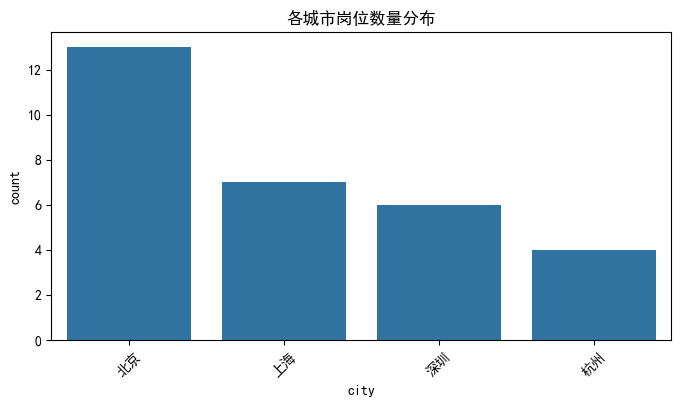

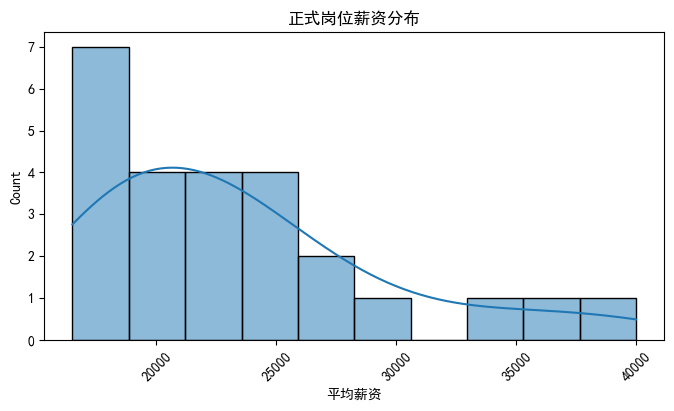

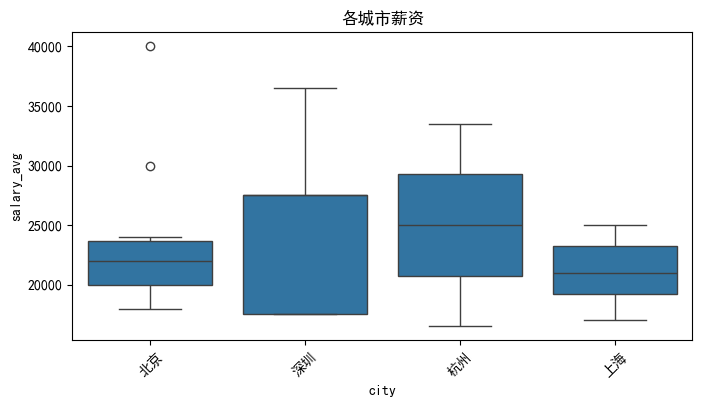

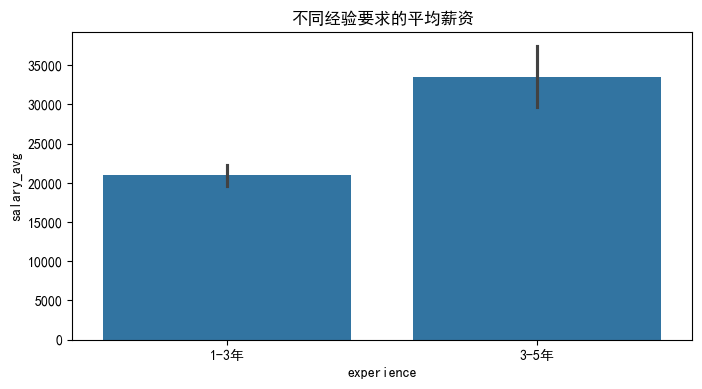

Text(0.5, 1.0, '经验×薪资')

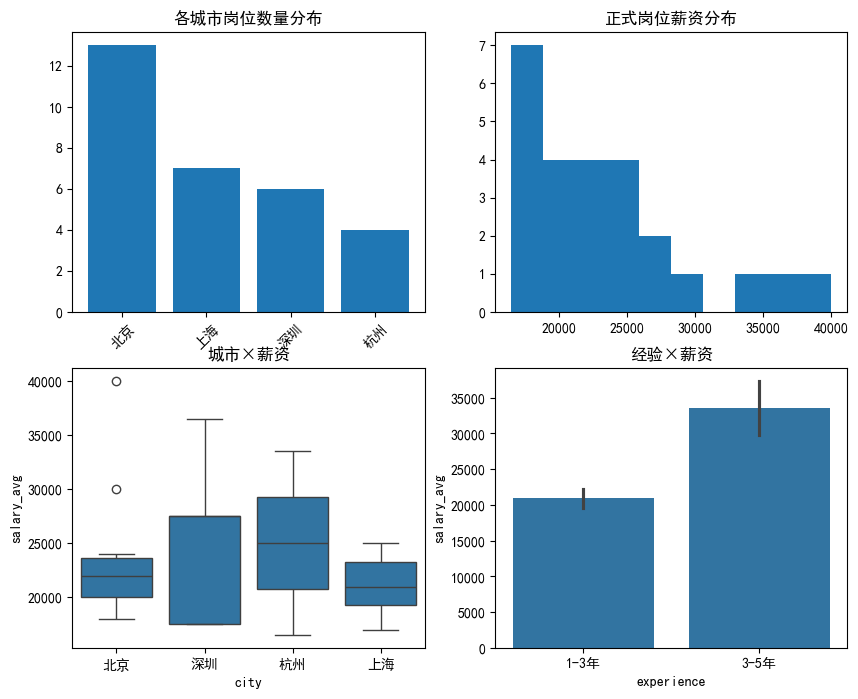

In [16]:
#可视化
# 各城市岗位数量柱状图（正式岗位）
plt.figure(figsize=(8,4))
sns.countplot(data=df,x="city",order=df["city"].value_counts().index)
plt.title("各城市岗位数量分布")
plt.xticks(rotation=45)
plt.show()
# 正式岗位薪资分布直方图（加 KDE 密度曲线）
plt.figure(figsize=(8,4))
sns.histplot(df_full["salary_avg"],bins=10,kde=True)
plt.title("正式岗位薪资分布")
plt.xlabel("平均薪资")
plt.xticks(rotation=45)
plt.show()
# 各城市薪资箱线图（正式岗位，按 city 分组）
plt.figure(figsize=(8,4))
sns.boxplot(data=df_full,x="city",y="salary_avg")
plt.title("各城市薪资")
plt.xticks(rotation=45)
plt.show()
# 经验要求×薪资分组柱状图
plt.figure(figsize=(8,4))
sns.barplot(data=df_full,x="experience",y="salary_avg")
plt.title("不同经验要求的平均薪资")
plt.show()

# 2×2 子图（整合以上4个图）
fig,axes=plt.subplots(2,2,figsize=(10,8))
axes[0,0].bar(df["city"].value_counts().index,df["city"].value_counts().values)
axes[0,0].set_title("各城市岗位数量分布")
axes[0,0].tick_params(axis="x",rotation=45)

axes[0,1].hist(df_full["salary_avg"],bins=10)
axes[0,1].set_title("正式岗位薪资分布")

sns.boxplot(data=df_full,x="city",y="salary_avg",ax=axes[1,0])
axes[1,0].set_title("城市×薪资")

sns.barplot(data=df_full,x="experience",y="salary_avg",ax=axes[1,1])
axes[1,1].set_title("经验×薪资")

In [19]:
#深度分析
# 用 pivot_table 按 city（行）和 experience（列）看 salary_avg 平均值，fill_value=0
pt= pd.pivot_table(df_full,values="salary_avg",index="city",columns="experience",aggfunc="mean",fill_value=0)
print(pt)
# 用 crosstab 统计各城市各经验要求的岗位数量
ct = pd.crosstab(df_full["city"],df["experience"])
print(ct)
#  和 salary_max 的相关系数
corr = df["salary_min"].corr(df["salary_max"])
print(corr)

experience          1-3年     3-5年
city                             
上海          21142.857143      0.0
北京          20875.000000  35000.0
杭州          20750.000000  33500.0
深圳          20833.333333  32000.0
experience  1-3年  3-5年
city                  
上海             7     0
北京             8     2
杭州             2     1
深圳             3     2
0.9973458339183238
